# 04 · Black Friday's impact on annual sales, by customer segment

**Question:** What is the impact of Black Friday on annual sales (in terms of both volume and revenue) by customer segment?

**Short answer:** **Black Friday is the busiest day of the year, but a small part of annual sales.** It brings about 4× a normal day's orders, yet only about 1.1% of the year's orders and 1.0–1.3% of its revenue. Its revenue fell 24% in 2025, and the response differs by segment: Young Parents and Fashion Shoppers reacted most in 2024, and Fitness Buffs were the only segment to grow in 2025.

**Business rules (from the challenge brief)**
- **Black Friday:** 20% off every order placed on Black Friday, by the customer's local date (Nov 29, 2024; Nov 28, 2025).
- **Referral:** referred customers get 10% off their first order (applied after Black Friday).
- **Shipping charged:** $7.99 under $50, $4.99 from $50 to $99.99, free from $100. **Carrier fee:** the company pays $4.99 per order.

**Approach**
- **Delivered orders only** (`is_revenue`), lines with a valid quantity.
- **Volume = orders and units. Revenue = item sales after discounts**, excluding shipping.
- **Profit per order = item profit − discounts + shipping charged − carrier fee.**
- **Year and Black Friday use the buyer's local date** (`order_datetime`), matching how the discount is applied.
- **Segment = `customer_segment`.** Orders from buyers who aren't in the customer table are shown as *Unknown*.
- **"× an average day"** compares Black Friday with the average of the other days of the same year.

## 1. Setup

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Project folder: same location as the cleaning notebook
USE_DRIVE = True
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/ecommerce-challenge"
elif IN_COLAB:
    BASE = "/content/ecommerce-challenge"
else:
    BASE = os.path.abspath("ecommerce-challenge")

CLEAN = os.path.join(BASE, "data", "clean")
pd.set_option("display.max_columns", 30, "display.width", 160)

# Business rules from the brief
REFERRAL_DISCOUNT = 0.10
BLACK_FRIDAY_DISCOUNT = 0.20
BLACK_FRIDAYS = pd.to_datetime(["2024-11-29", "2025-11-28"])   # add a date if the data covers more years
CARRIER_FEE = 4.99


def shipping_charged(item_total):
    # $7.99 under $50, $4.99 from $50 to $99.99, free from $100
    return np.select([item_total < 50, item_total < 100], [7.99, 4.99], 0.0)

Mounted at /content/drive


## 2. Load data

In [3]:
customers = pd.read_csv(os.path.join(CLEAN, "customers.csv"), dtype=str)
products = pd.read_csv(os.path.join(CLEAN, "products.csv"), dtype={"sku_id": str})
sales = pd.read_csv(os.path.join(CLEAN, "sales.csv"), dtype=str)

# CSV files store everything as text: restore the types we need
customers["is_referred"] = pd.to_numeric(customers.is_referred).astype("Int64")
sales["quantity"] = pd.to_numeric(sales.quantity)
sales["is_revenue"] = sales.is_revenue.eq("True")
sales["order_datetime"] = pd.to_datetime(sales.order_datetime)   # buyer's local time

## 3. Build one row per delivered order

Same rules as notebook 03: Black Friday discount first, then the referral discount, then shipping and profit.

In [4]:
# Delivered lines with a valid quantity, with price and margin attached
lines = sales[sales.is_revenue & sales.quantity.notna()].merge(
    products[["sku_id", "price", "profit_margin"]], on="sku_id", how="left")
assert lines.price.notna().all(), "some sales lines have no matching product"
lines["list_revenue"] = lines.quantity * lines.price
lines["item_profit"] = lines.list_revenue * lines.profit_margin

# One row per order
orders = lines.groupby("order_id").agg(
    buyer_id=("buyer_id", "first"),
    order_time=("order_datetime", "min"),
    units=("quantity", "sum"),
    list_revenue=("list_revenue", "sum"),
    item_profit=("item_profit", "sum"),
).reset_index()

# Black Friday: 20% off, by the buyer's local date
orders["is_black_friday"] = orders.order_time.dt.normalize().isin(BLACK_FRIDAYS)
orders["black_friday_discount"] = np.where(orders.is_black_friday, orders.list_revenue * BLACK_FRIDAY_DISCOUNT, 0.0)
orders["pre_referral_total"] = orders.list_revenue - orders.black_friday_discount

# Referral: 10% off a referred buyer's first delivered order
orders = orders.sort_values(["order_time", "order_id"])
has_buyer = orders.buyer_id.notna() & orders.order_time.notna()
orders["order_rank"] = orders[has_buyer].groupby("buyer_id").cumcount() + 1
orders = orders.merge(customers[["buyer_id", "is_referred", "customer_segment"]], on="buyer_id", how="left")
is_referral_order = orders.order_rank.eq(1) & orders.is_referred.eq(1).fillna(False)
orders["referral_discount"] = np.where(is_referral_order, orders.pre_referral_total * REFERRAL_DISCOUNT, 0.0)

# Revenue (items after discounts), shipping and profit
orders["item_revenue"] = orders.pre_referral_total - orders.referral_discount
orders["shipping"] = shipping_charged(orders.item_revenue)
orders["profit"] = (orders.item_profit - orders.black_friday_discount - orders.referral_discount
                    + orders.shipping - CARRIER_FEE)

# Keep orders with a date; label buyers not in the customer table
orders = orders.dropna(subset=["order_time"])
orders["year"] = orders.order_time.dt.year
orders["date"] = orders.order_time.dt.normalize()
orders["customer_segment"] = orders.customer_segment.fillna("Unknown")

print(f"{len(orders):,} delivered orders, {orders.is_black_friday.sum():,} of them on Black Friday")

234,968 delivered orders, 2,574 of them on Black Friday


## 4. Overall impact, by year

In [5]:
def bf_summary(d):
    # Black Friday vs the rest of the year for one group of orders (one year)
    bf, other = d[d.is_black_friday], d[~d.is_black_friday]
    other_days = d.date.dt.year.iloc[0]
    other_days = (366 if pd.Timestamp(year=other_days, month=12, day=31).dayofyear == 366 else 365) - 1
    return pd.Series({
        "bf_orders": len(bf),
        "bf_order_share": len(bf) / len(d),
        "bf_units": bf.units.sum(),
        "bf_revenue": bf.item_revenue.sum(),
        "bf_revenue_share": bf.item_revenue.sum() / d.item_revenue.sum(),
        "orders_x_avg_day": len(bf) / (len(other) / other_days),
        "revenue_x_avg_day": bf.item_revenue.sum() / (other.item_revenue.sum() / other_days),
        "discount_cost": bf.black_friday_discount.sum(),
        "bf_order_value": bf.item_revenue.mean(),
        "bf_order_value_before_discount": bf.list_revenue.mean(),
        "other_order_value": other.item_revenue.mean(),
        "bf_units_per_order": bf.units.mean(),
        "other_units_per_order": other.units.mean(),
        "bf_profit_per_order": bf.profit.mean(),
        "other_profit_per_order": other.profit.mean(),
        "bf_profit_share": bf.profit.sum() / d.profit.sum(),
        "avg_day_orders": len(other) / other_days,
        "avg_day_revenue": other.item_revenue.sum() / other_days,
    })


overall = orders.groupby("year").apply(bf_summary).T

# Readable row labels for display
LABELS = {
    "bf_orders": "Black Friday orders",
    "bf_order_share": "Share of the year's orders",
    "bf_units": "Black Friday units",
    "bf_revenue": "Black Friday revenue (after discount)",
    "bf_revenue_share": "Share of the year's revenue",
    "orders_x_avg_day": "Orders vs an average day",
    "revenue_x_avg_day": "Revenue vs an average day",
    "discount_cost": "Cost of the 20% discount",
    "bf_order_value": "Order value, Black Friday (after discount)",
    "bf_order_value_before_discount": "Order value, Black Friday (before discount)",
    "other_order_value": "Order value, other days",
    "bf_units_per_order": "Units per order, Black Friday",
    "other_units_per_order": "Units per order, other days",
    "bf_profit_per_order": "Profit per order, Black Friday",
    "other_profit_per_order": "Profit per order, other days",
    "bf_profit_share": "Share of the year's profit",
    "avg_day_orders": "Average day: orders",
    "avg_day_revenue": "Average day: revenue",
}

fmt = {
    "bf_orders": "{:,.0f}", "bf_units": "{:,.0f}", "bf_revenue": "${:,.0f}", "discount_cost": "${:,.0f}",
    "avg_day_orders": "{:,.0f}", "avg_day_revenue": "${:,.0f}",
    "orders_x_avg_day": "{:.1f}×", "revenue_x_avg_day": "{:.1f}×",
    "bf_units_per_order": "{:.2f}", "other_units_per_order": "{:.2f}",
}
pct_rows = ["bf_order_share", "bf_revenue_share", "bf_profit_share"]
money_rows = ["bf_order_value", "bf_order_value_before_discount", "other_order_value",
              "bf_profit_per_order", "other_profit_per_order"]
shown = overall.astype(object).copy()
for row in overall.index:
    f = fmt.get(row, "{:.2%}" if row in pct_rows else "${:,.2f}")
    shown.loc[row] = [f.format(v) for v in overall.loc[row]]
shown.columns = [str(c) for c in shown.columns]
shown.index = shown.index.map(LABELS)
shown

/tmp/ipykernel_688/3850273430.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  overall = orders.groupby("year").apply(bf_summary).T


,2024,2025
Black Friday orders,"1,316","1,258"
Share of the year's orders,1.12%,1.07%
Black Friday units,"2,918","2,772"
Black Friday revenue (after discount),"$118,346","$89,535"
Share of the year's revenue,1.28%,0.96%
Orders vs an average day,4.1×,3.9×
Revenue vs an average day,4.7×,3.5×
Cost of the 20% discount,"$29,587","$22,384"
"Order value, Black Friday (after discount)",$89.93,$71.17
"Order value, Black Friday (before discount)",$112.41,$88.97


In [6]:
# Year-over-year change on Black Friday
yoy = (overall[2025] / overall[2024] - 1)[["bf_orders", "bf_revenue", "bf_order_value_before_discount",
                                             "bf_profit_per_order"]]
print("Black Friday, 2025 vs 2024:")
for k, v in yoy.items():
    print(f"  {k:32s} {v:+.1%}")
print(f"\nProfit per order on Black Friday vs other days: "
      f"2024 {overall.loc['bf_profit_per_order', 2024] / overall.loc['other_profit_per_order', 2024] - 1:+.1%}, "
      f"2025 {overall.loc['bf_profit_per_order', 2025] / overall.loc['other_profit_per_order', 2025] - 1:+.1%}")

Black Friday, 2025 vs 2024:
  bf_orders                        -4.4%
  bf_revenue                       -24.3%
  bf_order_value_before_discount   -20.9%
  bf_profit_per_order              -30.0%

Profit per order on Black Friday vs other days: 2024 -9.1%, 2025 -36.8%


## 5. The days around Black Friday

Orders and revenue from the Monday before Thanksgiving to Cyber Monday. Only Black Friday has the 20% discount.

In [7]:
rows = []
for bf in BLACK_FRIDAYS:
    for d in pd.date_range(bf - pd.Timedelta(days=4), bf + pd.Timedelta(days=3)):
        day = orders[orders.date == d]
        rows.append({"year": bf.year, "date": d.date(), "day": d.day_name(),
                     "orders": len(day), "revenue": day.item_revenue.sum()})
around = pd.DataFrame(rows).set_index(["year", "date"])
around.style.format({"orders": "{:,}", "revenue": "${:,.0f}"})

## 6. By customer segment

Revenue is after discounts. "× avg day" compares Black Friday with that segment's average day in the same year.

In [8]:
seg = orders.groupby(["customer_segment", "year"]).apply(bf_summary)
cols = ["bf_orders", "bf_order_share", "bf_revenue", "bf_revenue_share", "revenue_x_avg_day",
        "bf_order_value", "other_order_value", "discount_cost", "bf_profit_share"]
by_segment = seg[cols].unstack("year")
by_segment = by_segment.sort_values(("bf_revenue", 2024), ascending=False)
# Keep 'Unknown' at the bottom
by_segment = pd.concat([by_segment.drop(index="Unknown"), by_segment.loc[["Unknown"]]])
by_segment.index = by_segment.index.str.replace("Unknown", "Unknown (buyer not in customers)")
by_segment.index.name = "Segment"

seg_fmt = {}
for c in by_segment.columns:
    name = c[0]
    seg_fmt[c] = ("{:,.0f}" if name == "bf_orders" else
                  "{:.2%}" if name in pct_rows else
                  "{:.1f}×" if name == "revenue_x_avg_day" else
                  "${:,.0f}" if name in ["bf_revenue", "discount_cost"] else "${:,.2f}")
seg_labels = {"bf_orders": "BF orders", "bf_order_share": "Share of year's orders", "bf_revenue": "BF revenue",
              "bf_revenue_share": "Share of year's revenue", "revenue_x_avg_day": "Revenue vs avg day",
              "bf_order_value": "BF order value", "other_order_value": "Other-day order value",
              "discount_cost": "Discount cost", "bf_profit_share": "Share of year's profit"}
(by_segment.style.format(seg_fmt)
           .background_gradient(cmap="Blues", subset=[("revenue_x_avg_day", 2024), ("revenue_x_avg_day", 2025)])
           .format_index(lambda c: seg_labels.get(c, c), axis=1, level=0))

/tmp/ipykernel_688/426644124.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  seg = orders.groupby(["customer_segment", "year"]).apply(bf_summary)


In [10]:
# Year-over-year change on Black Friday, by segment
seg_yoy = pd.DataFrame({
    "orders": by_segment[("bf_orders", 2025)] / by_segment[("bf_orders", 2024)] - 1,
    "revenue": by_segment[("bf_revenue", 2025)] / by_segment[("bf_revenue", 2024)] - 1,
}).sort_values("revenue", ascending=False)
seg_yoy.index.name = "Black Friday 2025 vs 2024"
seg_yoy.style.format("{:+.1%}")

,orders,revenue
Black Friday 2025 vs 2024,,
Fitness Buff,+15.6%,+6.6%
Cozy Homemaker,-2.4%,-4.3%
Bargain Hunter,-2.0%,-18.3%
Unknown (buyer not in customers),+19.0%,-18.9%
Home Organizer,+1.3%,-25.2%
Fashion Shopper,-7.0%,-27.7%
Tech Enthusiast,-19.1%,-30.6%
Beauty Lover,-17.0%,-33.8%
Young Parent,-13.1%,-36.0%


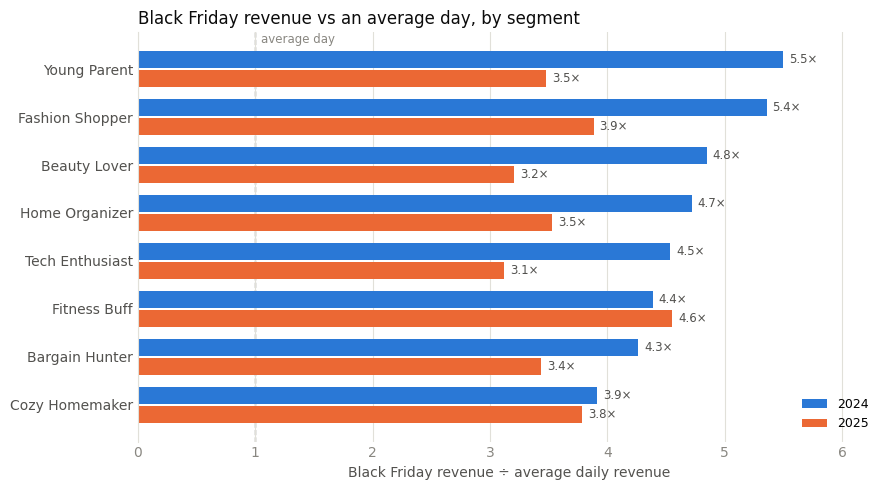

In [11]:
# Chart: Black Friday revenue vs an average day, by segment and year
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#52514e", "#898781", "#e1e0d9"

lift = by_segment[[("revenue_x_avg_day", 2024), ("revenue_x_avg_day", 2025)]].droplevel(0, axis=1)
lift = lift.drop(index=[i for i in lift.index if i.startswith("Unknown")]).sort_values(2024)

y = np.arange(len(lift))
h = 0.36
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y + h / 2 + 0.02, lift[2024], height=h, color=BLUE, label="2024", zorder=2)
ax.barh(y - h / 2 - 0.02, lift[2025], height=h, color=ORANGE, label="2025", zorder=2)
for yy, v in zip(y, lift[2024]):
    ax.text(v + 0.05, yy + h / 2 + 0.02, f"{v:.1f}×", va="center", fontsize=8.5, color=INK)
for yy, v in zip(y, lift[2025]):
    ax.text(v + 0.05, yy - h / 2 - 0.02, f"{v:.1f}×", va="center", fontsize=8.5, color=INK)
ax.axvline(1, color=MUTED, linewidth=1, linestyle="--", zorder=1)
ax.text(1.05, len(lift) - 0.45, "average day", fontsize=8.5, color=MUTED)
ax.set_yticks(y)
ax.set_yticklabels(lift.index)
ax.set_title("Black Friday revenue vs an average day, by segment", loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlabel("Black Friday revenue ÷ average daily revenue", color=INK)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.tick_params(colors=MUTED, length=0)
ax.tick_params(axis="y", colors=INK)
for s in ["top", "right", "bottom"]:
    ax.spines[s].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.set_xlim(0, lift.values.max() * 1.15)
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## 7. Conclusion

**Black Friday is a big day but a small share of the year, and it earned less per order in 2025.**

**Overall**
- **Volume:** 1,316 orders in 2024 and 1,258 in 2025, about 4× an average day (about 318 orders), but only 1.1% of each year's orders.
- **Revenue:** $118.3k in 2024 (1.28% of the year) and $89.5k in 2025 (0.96%), after the 20% discount. The discount itself cost $29.6k and $22.4k.
- **Bigger baskets, lower profit.** Black Friday orders have about 28% more units (2.2 vs 1.74), but the discount outweighs that. Profit per order was 9% below other days in 2024 ($31.94 vs $35.16) and 37% below in 2025 ($22.36 vs $35.36).
- **2025 was weaker.** Orders fell only 4%, but revenue fell 24%, because the average order before discount dropped from $112.41 to $88.97.
- **Some sales are pulled forward.** The Saturday after Black Friday is the slowest day of the week around it (196 orders in 2024, 225 in 2025). Cyber Monday is strong without any discount: about 740 orders and $70–73k.

**By customer segment**
- **Tech Enthusiasts bring the most Black Friday revenue** ($32.2k in 2024, $22.3k in 2025) because of their large baskets. But they have the lowest share of their year's orders on Black Friday (0.93%, then 0.75%), and they receive the largest share of the discount ($8.0k in 2024). Much of that discount likely went on purchases they would have made anyway.
- **Young Parents and Fashion Shoppers responded most in 2024** (5.5× and 5.4× their average daily revenue), then fell back hardest in 2025 (revenue −36% and −28%).
- **Fitness Buffs are the only segment that grew in 2025:** orders +16%, revenue +7%, and the highest lift that year (4.6×).
- **Cozy Homemakers respond least in 2024** (3.9×). Their Black Friday orders are smaller than their usual order ($53 vs $59).
- **Black Friday's share of annual profit fell in every segment in 2025**, from 0.8–1.2% to 0.5–1.0%. Young Parents fell furthest, to 0.50%.

**For marketing:** the 20% discount costs $22–30k a year to win roughly 950–1,000 extra orders over a normal day, and profit per Black Friday order is falling. Aiming the offer at segments that respond (Fitness Buffs, Fashion Shoppers, Young Parents), rather than giving the deepest discount dollars to Tech Enthusiasts, would protect margin. This is a judgment and is worth testing before rolling it out.

**Limits**
- **Two Black Fridays only,** so year-over-year differences between segments may partly be noise.
- **"× an average day" includes weekends.** Black Friday is a Friday, so against a typical Friday the lift would be a little lower.
- **Profit uses today's catalog price**, so past price changes aren't captured.
- *Unknown* = orders from buyers who aren't in the customer table (about 5% of orders).